# **분류 모델**

---



**(코랩에서)한글 폰트 지정하는 방법**

In [13]:
# 코랩에서 실행
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import shutil

# ── 1. 나눔 폰트 설치 ──────────────────────────────────────────
!apt-get install -y fonts-nanum > /dev/null 2>&1

# ── 2. matplotlib 캐시 디렉터리 삭제 ──────────────────────────
shutil.rmtree(mpl.get_cachedir(), ignore_errors=True)

# ── 3. 폰트 등록  ───────────────────────────────────
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (6, 4)



---



- <a href="#분류">분류(Classification)</a>
- <a href="#로지스틱 회귀">로지스틱 회귀(Logistic Regression)</a>


--------------

## ⏺️ <a name="분류">분류(Classification)</a>

### **Binary Classification**

In [1]:
import math

# -------------------------------------------------
# 1. 데이터
# x1 : 긍정어 수
# x2 : 부정어 수
# y  : 정답 (1=Positive, 0=Negative)
# -------------------------------------------------
data = [
    {"review": "Very good quality though", "x1": 1, "x2": 0, "y": 1},
    {"review": "The design is very odd",    "x1": 0, "x2": 1, "y": 0}
]

# -------------------------------------------------
# 2. 학습된 파라미터라고 가정
# -------------------------------------------------
w1 = 2.0
w2 = -2.5
b  = -0.5


# -------------------------------------------------
# 3. Sigmoid 함수
# z를 0~1 사이의 확률로 변환
# -------------------------------------------------
def sigmoid(z):
    return 1 / (1 + math.exp(-z))


# -------------------------------------------------
# 4. Binary Cross Entropy
# -------------------------------------------------
def binary_cross_entropy(y, p):
    return -(y * math.log(p) + (1 - y) * math.log(1 - p))


# -------------------------------------------------
# 5. 예측
# -------------------------------------------------
total_loss = 0

for d in data:

    x1 = d["x1"]
    x2 = d["x2"]
    y  = d["y"]

    # ① 선형 결합
    z = w1*x1 + w2*x2 + b

    # ② Sigmoid → 확률
    p = sigmoid(z)

    # ③ 0.5를 기준으로 분류
    y_hat = 1 if p >= 0.5 else 0

    # ④ Binary Cross Entropy Loss
    loss = binary_cross_entropy(y, p)

    total_loss += loss

    print("=" * 50)
    print("리뷰 :", d["review"])
    print(f"x1={x1}, x2={x2}, 정답 y={y}")
    print()

    print(f"① 선형결합 z = {w1}×{x1} + ({w2})×{x2} + ({b})")
    print(f"   z = {z:.3f}")

    print(f"② Sigmoid 확률 p = {p:.3f}")

    print(f"③ 예측 결과 y_hat = {y_hat}")

    print(f"④ Binary Cross Entropy Loss = {loss:.3f}")


# -------------------------------------------------
# 평균 손실
# -------------------------------------------------
average_loss = total_loss / len(data)

print("\n" + "=" * 50)
print(f"평균 손실 = {average_loss:.3f}")

리뷰 : Very good quality though
x1=1, x2=0, 정답 y=1

① 선형결합 z = 2.0×1 + (-2.5)×0 + (-0.5)
   z = 1.500
② Sigmoid 확률 p = 0.818
③ 예측 결과 y_hat = 1
④ Binary Cross Entropy Loss = 0.201
리뷰 : The design is very odd
x1=0, x2=1, 정답 y=0

① 선형결합 z = 2.0×0 + (-2.5)×1 + (-0.5)
   z = -3.000
② Sigmoid 확률 p = 0.047
③ 예측 결과 y_hat = 0
④ Binary Cross Entropy Loss = 0.049

평균 손실 = 0.125


### **Multi-Class Classificatio**n

In [4]:
import numpy as np

# ============================================
# 1. 클래스 이름
# ============================================
classes = ["Dog", "Cat", "Rabbit", "Tiger"]


# ============================================
# 2. 모델이 출력한 점수(logit)
#    아직 확률이 아님
# ============================================
z = np.array([2.0, 1.0, 0.1, -1.0])

print("Logit :", z)


# ============================================
# 3. Softmax 함수
#    각 점수를 0~1 사이의 확률로 변환
#    전체 합은 1
# ============================================
def softmax(z):
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z)


p = softmax(z)

print("\nSoftmax 확률")

for cls, prob in zip(classes, p):
    print(f"{cls:7s} : {prob:.3f}")

print(f"\n확률 합 : {np.sum(p):.3f}")


# ============================================
# 4. 가장 확률이 높은 클래스 선택
# ============================================
pred_index = np.argmax(p)
pred_class = classes[pred_index]

print("\n예측 클래스 :", pred_class)
print("최대 확률   :", round(p[pred_index], 3))


# ============================================
# 5. 정답 설정
#    실제 정답 = Dog
#
#    Dog    = [1, 0, 0, 0]
#    Cat    = [0, 1, 0, 0]
#    Rabbit = [0, 0, 1, 0]
#    Tiger  = [0, 0, 0, 1]
# ============================================
y = np.array([1, 0, 0, 0])


# ============================================
# 6. Categorical Cross Entropy 계산
#
# L = - Σ y_k log(p_k)
#
# one-hot에서는 정답 클래스의
# 확률만 사용하면 됨
# ============================================
loss = -np.sum(y * np.log(p))

print("\n정답 :", classes[np.argmax(y)])
print(f"Cross Entropy Loss : {loss:.3f}")

Logit : [ 2.   1.   0.1 -1. ]

Softmax 확률
Dog     : 0.638
Cat     : 0.235
Rabbit  : 0.095
Tiger   : 0.032

확률 합 : 1.000

예측 클래스 : Dog
최대 확률   : 0.638

정답 : Dog
Cross Entropy Loss : 0.449


- [참고] MSE와 CE의 Gradient 비교
> Sigmoid + MSE는 모델이 확신을 가지고 틀렸을 때 Sigmoid 미분값이 매우 작아져 학습이 느려질 수 있지만, Sigmoid + BCE는 Gradient가 p-y가 되어 틀린 정도에 비례하는 강한 학습 신호를 유지한다.  CE는 주로 분류에서 사용한다.

정답 y = 1
      z         확률 p       MSE Gradient       BCE Gradient
  -10.0     0.000045          -0.000091          -0.999955
   -5.0     0.006693          -0.013207          -0.993307
   -3.0     0.047426          -0.086068          -0.952574
   -1.0     0.268941          -0.287470          -0.731059
    0.0     0.500000          -0.250000          -0.500000
    1.0     0.731059          -0.105754          -0.268941
    3.0     0.952574          -0.004285          -0.047426
    5.0     0.993307          -0.000089          -0.006693
   10.0     0.999955          -0.000000          -0.000045


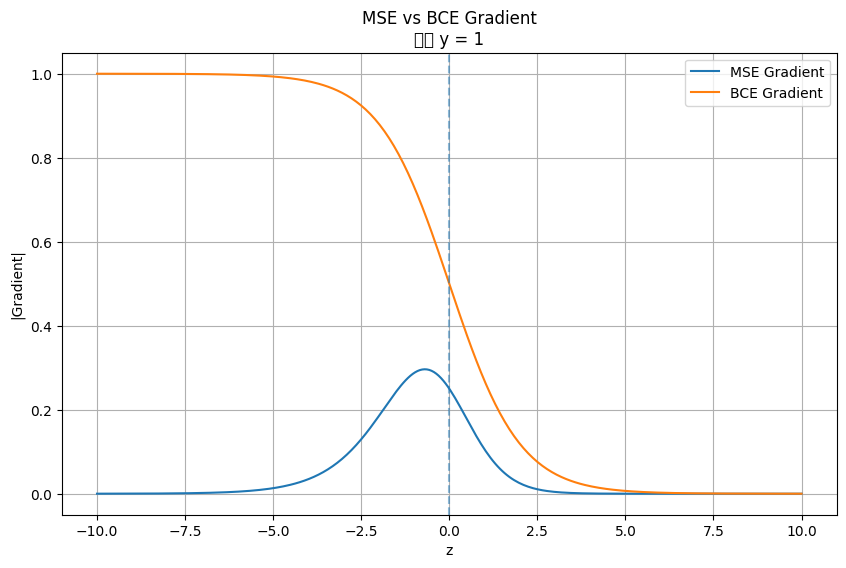

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# 1. Sigmoid 함수
# ============================================
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# ============================================
# 2. 정답 설정
# ============================================
# 정답은 Positive = 1
y = 1


# ============================================
# 3. 다양한 z 값 준비
#
# z가 음수로 매우 작으면
# sigmoid(z)는 0에 가까워진다.
#
# 즉 정답은 1인데 모델은 0이라고
# 강하게 잘못 예측하는 상황
# ============================================
z_values = np.array([-10, -5, -3, -1, 0, 1, 3, 5, 10])

p_values = sigmoid(z_values)


# ============================================
# 4. MSE Gradient
#
# MSE = (y - p)^2
#
# p = sigmoid(z)
#
# dMSE/dz =
# 2(p-y) * p(1-p)
# ============================================
mse_gradient = 2 * (p_values - y) * p_values * (1 - p_values)


# ============================================
# 5. Binary Cross Entropy Gradient
#
# BCE = -[y log(p) + (1-y)log(1-p)]
#
# sigmoid + BCE를 미분하면 매우 간단해짐
#
# dBCE/dz = p - y
# ============================================
bce_gradient = p_values - y


# ============================================
# 6. 결과 출력
# ============================================
print("=" * 65)
print("정답 y = 1")
print("=" * 65)

print(f"{'z':>7} {'확률 p':>12} {'MSE Gradient':>18} {'BCE Gradient':>18}")

for z, p, gmse, gbce in zip(
    z_values,
    p_values,
    mse_gradient,
    bce_gradient
):
    print(f"{z:7.1f} {p:12.6f} {gmse:18.6f} {gbce:18.6f}")


# ============================================
# 7. Gradient 크기 시각화
# ============================================
z = np.linspace(-10, 10, 300)
p = sigmoid(z)
mse_grad = np.abs( 2 * (p - y) * p * (1 - p) )
bce_grad = np.abs( p - y )


plt.figure(figsize=(10, 6))
plt.plot(
    z,
    mse_grad,
    label="MSE Gradient"
)
plt.plot(
    z,
    bce_grad,
    label="BCE Gradient"
)
plt.axvline(
    x=0,
    linestyle="--",
    alpha=0.5
)
plt.xlabel("z")
plt.ylabel("|Gradient|")
plt.title(
    "MSE vs BCE Gradient\n"
    "정답 y = 1"
)
plt.legend()
plt.grid()
plt.show()

- SVM으로 OvR vs. OvO 비교
    - SVM(Support Vector Machine)은 클래스 사이의 간격(Margin)을 가장 크게 만드는 결정 경계(Hyperplane)를 찾아 데이터를 분류하는 알고리즘

In [6]:
# ============================================================
# SVM Multi-Class Classification
# One-vs-Rest(OvR) vs One-vs-One(OvO)
# ============================================================
import numpy as np

from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier

from sklearn.metrics import accuracy_score


# ------------------------------------------------------------
# 1. 4개의 클래스 데이터 생성
#
# 0 = Dog
# 1 = Cat
# 2 = Rabbit
# 3 = Tiger
# ------------------------------------------------------------

class_names = np.array([
    "Dog",
    "Cat",
    "Rabbit",
    "Tiger"
])

X, y = make_blobs(
    n_samples=400,
    centers=4,
    n_features=2,
    cluster_std=1.3,
    random_state=42
)

print("X shape :", X.shape)
print("y shape :", y.shape)

print("\n클래스")
for i, name in enumerate(class_names):
    print(i, "=", name)


# ------------------------------------------------------------
# 2. Train / Test 분리
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


# ------------------------------------------------------------
# 3. SVM은 Feature Scale에 영향을 많이 받으므로
#    StandardScaler 적용
# ------------------------------------------------------------
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ============================================================
# 4. One-vs-Rest
#
# Dog    vs 나머지
# Cat    vs 나머지
# Rabbit vs 나머지
# Tiger  vs 나머지
#
# 총 모델 수 = N = 4
# ============================================================
ovr = OneVsRestClassifier(
    SVC(
        kernel="linear",
        probability=True,
        random_state=42
    )
)

ovr.fit(X_train, y_train)

print("\n" + "=" * 60)
print("One-vs-Rest")
print("=" * 60)

print("이진 분류기 개수 :", len(ovr.estimators_))


# 예측
ovr_pred = ovr.predict(X_test)

print(
    "정확도 :",
    round(accuracy_score(y_test, ovr_pred), 3)
)


# ============================================================
# 5. One-vs-One
#
# Dog    vs Cat
# Dog    vs Rabbit
# Dog    vs Tiger
# Cat    vs Rabbit
# Cat    vs Tiger
# Rabbit vs Tiger
#
# 총 모델 수
#
# N(N-1)/2
#
# = 4 × 3 / 2
# = 6
# ============================================================
ovo = OneVsOneClassifier(
    SVC(
        kernel="linear"
    )
)

ovo.fit(X_train, y_train)

print("\n" + "=" * 60)
print("One-vs-One")
print("=" * 60)

print("이진 분류기 개수 :", len(ovo.estimators_))


# 예측
ovo_pred = ovo.predict(X_test)

print(
    "정확도 :",
    round(accuracy_score(y_test, ovo_pred), 3)
)


# ============================================================
# 6. 하나의 테스트 데이터 선택
# ============================================================
sample = X_test[0].reshape(1, -1)

true_class = y_test[0]


print("\n" + "=" * 60)
print("하나의 샘플 예측")
print("=" * 60)

print(
    "실제 정답 :",
    class_names[true_class]
)


# ------------------------------------------------------------
# 7. OvR 예측
# ------------------------------------------------------------
ovr_prediction = ovr.predict(sample)[0]

print(
    "\nOvR 예측 :",
    class_names[ovr_prediction]
)


# ------------------------------------------------------------
# 각 OvR 이진 SVM의 확률 확인
#
# Dog vs Rest
# Cat vs Rest
# Rabbit vs Rest
# Tiger vs Rest
# ------------------------------------------------------------
print("\n[OvR 각 이진 분류기 결과]")

for i, estimator in enumerate(ovr.estimators_):

    # 각 binary SVM에서
    # 해당 클래스로 분류할 확률
    probability = estimator.predict_proba(sample)[0, 1]

    print(
        f"{class_names[i]:7s} vs Rest"
        f" → {probability:.3f}"
    )


# ------------------------------------------------------------
# 8. OvO 예측
# ------------------------------------------------------------
ovo_prediction = ovo.predict(sample)[0]

print(
    "\nOvO 최종 예측 :",
    class_names[ovo_prediction]
)


# ------------------------------------------------------------
# 9. OvO의 클래스별 decision score
# ------------------------------------------------------------
scores = ovo.decision_function(sample)[0]

print("\n[OvO 클래스별 Score]")

for cls, score in zip(class_names, scores):

    print(
        f"{cls:7s} : {score:.3f}"
    )


print(
    "\n최종 선택 :",
    class_names[np.argmax(scores)]
)

X shape : (400, 2)
y shape : (400,)

클래스
0 = Dog
1 = Cat
2 = Rabbit
3 = Tiger

One-vs-Rest
이진 분류기 개수 : 4
정확도 : 1.0

One-vs-One
이진 분류기 개수 : 6
정확도 : 0.988

하나의 샘플 예측
실제 정답 : Rabbit

OvR 예측 : Rabbit

[OvR 각 이진 분류기 결과]
Dog     vs Rest → 0.000
Cat     vs Rest → 0.000
Rabbit  vs Rest → 0.997
Tiger   vs Rest → 0.110

OvO 최종 예측 : Rabbit

[OvO 클래스별 Score]
Dog     : 0.717
Cat     : -0.259
Rabbit  : 3.283
Tiger   : 2.259

최종 선택 : Rabbit


### **Multi-Label Classificatio**n

In [10]:
import numpy as np
import pandas as pd

# ============================================================
# Jumanji (1995) 영화 장르 Multi-Label Classification 예제
# ============================================================
# 1. 장르(Label)
labels = [
    "Adventure",
    "Comedy",
    "Fantasy",
    "Crime",
    "Children"
]

# 2. 모델이 출력한 Logit
# 아직 확률이 아님
z = np.array([
     2.2,   # Adventure
    -1.5,   # Comedy
     1.4,   # Fantasy
    -2.5,   # Crime
     0.3    # Children
])

# 3. 실제 정답
# 1 = 해당 장르
# 0 = 해당 장르 아님
y = np.array([
    1,      # Adventure
    0,      # Comedy
    1,      # Fantasy
    0,      # Crime
    1       # Children
])


# ============================================================
# 4. Sigmoid 함수
# 각 장르를 독립적으로 확률로 변환
# ============================================================
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


p = sigmoid(z)


# ============================================================
# 5. 임계값 0.5를 기준으로 장르 선택
# ============================================================
threshold = 0.5

y_pred = (p >= threshold).astype(int)


# ============================================================
# 6. Binary Cross Entropy
#
# BCE = -[y log(p) + (1-y) log(1-p)]
#
# Multi-Label에서는 각 Label별 BCE를 계산한 후 평균
# ============================================================
bce = -(
    y * np.log(p)
    + (1 - y) * np.log(1 - p)
)

mean_bce = np.mean(bce)


# ============================================================
# 7. 결과를 표로 출력
# ============================================================
result = pd.DataFrame({
    "Label": labels,
    "Logit(z)": z,
    "Probability(p)": p,
    "Prediction": y_pred,
    "Target(y)": y,
    "BCE": bce
})

print(result.round(3))


# ============================================================
# 8. 최종 예측 장르
# ============================================================
predicted_genres = [
    label
    for label, pred in zip(labels, y_pred)
    if pred == 1
]

actual_genres = [
    label
    for label, target in zip(labels, y)
    if target == 1
]


print("\n==============================")
print("영화 : Jumanji (1995)")
print("==============================")

print("예측 장르 :", predicted_genres)
print("정답 장르 :", actual_genres)

print("\n확률의 합 :", round(np.sum(p), 3))
print("평균 BCE Loss :", round(mean_bce, 3))

       Label  Logit(z)  Probability(p)  Prediction  Target(y)    BCE
0  Adventure       2.2           0.900           1          1  0.105
1     Comedy      -1.5           0.182           0          0  0.201
2    Fantasy       1.4           0.802           1          1  0.220
3      Crime      -2.5           0.076           0          0  0.079
4   Children       0.3           0.574           1          1  0.554

영화 : Jumanji (1995)
예측 장르 : ['Adventure', 'Fantasy', 'Children']
정답 장르 : ['Adventure', 'Fantasy', 'Children']

확률의 합 : 2.535
평균 BCE Loss : 0.232


### **예제 1: 타이타닉 생존 예측 (이진 분류)**

--- 승객별 생존 확률 및 최종 예측 결과 ---
승객 1: 생존 확률 0.89  ->  예측: 1 (실제: 1) ✅
승객 2: 생존 확률 0.72  ->  예측: 1 (실제: 1) ✅
승객 3: 생존 확률 0.63  ->  예측: 1 (실제: 0) ❌
승객 4: 생존 확률 0.93  ->  예측: 1 (실제: 1) ✅
승객 5: 생존 확률 0.41  ->  예측: 0 (실제: 0) ✅
승객 6: 생존 확률 0.76  ->  예측: 1 (실제: 1) ✅
승객 7: 생존 확률 0.76  ->  예측: 1 (실제: 1) ✅
승객 8: 생존 확률 0.85  ->  예측: 1 (실제: 1) ✅
승객 9: 생존 확률 0.13  ->  예측: 0 (실제: 0) ✅
승객 10: 생존 확률 0.92  ->  예측: 1 (실제: 1) ✅
----------------------------------------

--- 모델 예측 성능 시각화 ---


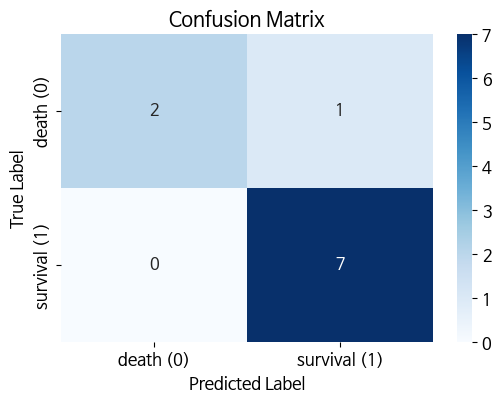

In [16]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 간단한 타이타닉 데이터 생성 (실제로는 kaggle에서 다운로드)
data = {
    'Pclass': [1, 2, 3, 1, 2, 3, 1, 2, 3, 1],
    'Sex': ['male', 'female', 'male', 'female', 'male', 'female', 'male', 'female', 'male', 'female'],
    'Age': [25, 35, 20, 28, 40, 22, 35, 27, 45, 30],
    'Survived': [1, 1, 0, 1, 0, 1, 1, 1, 0, 1]
}

df = pd.DataFrame(data)

# 성별을 숫자로 변환
le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex']) # female: 0, male: 1

# 특성과 타겟 분리
X = df[['Pclass', 'Sex', 'Age']]
y = df['Survived']

# 로지스틱 회귀 모델
log_model = LogisticRegression()
log_model.fit(X, y)


# 예측 확률과 최종 예측 결과를 미리 계산
probabilities = log_model.predict_proba(X)
binary_predictions = log_model.predict(X)

print("--- 승객별 생존 확률 및 최종 예측 결과 ---")
# 하나의 반복문으로 각 승객의 확률과 예측 결과를 함께 출력
for i in range(len(X)):
    # 생존 확률 (1일 확률)
    survival_prob = probabilities[i][1]
    # 최종 예측 (0 또는 1)
    prediction = binary_predictions[i]
    # 실제 값
    actual = y[i]
    # 예측과 실제 값 비교
    result_icon = "✅" if prediction == actual else "❌"

    print(f"승객 {i+1}: 생존 확률 {survival_prob:.2f}  ->  예측: {prediction} (실제: {actual}) {result_icon}")

print("-" * 40)


# 성능 평가를 위한 혼동 행렬(Confusion Matrix) 시각화
print("\n--- 모델 예측 성능 시각화 ---")
cm = confusion_matrix(y, binary_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['death (0)', 'survival (1)'],
            yticklabels=['death (0)', 'survival (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

### **예제 2: 텍스트 감정 분석 (Multi-class)**
- 참고 : https://www.kaggle.com/datasets/praveengovi/emotions-dataset-for-nlp

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import numpy as np

# 1. 데이터 로딩 및 준비
# Kaggle에서 다운로드한 데이터를 불러옵니다.
# 데이터는 세미콜론(;)으로 구분되어 있고, 헤더가 없습니다.
try:
    df_train = pd.read_csv('multi-class-train.txt', sep=';', header=None, names=['text', 'emotion'])
    df_val = pd.read_csv('multi-class-val.txt', sep=';', header=None, names=['text', 'emotion'])

    # 훈련 데이터와 검증 데이터를 합쳐서 전체 학습 데이터로 사용합니다.
    df_full = pd.concat([df_train, df_val], ignore_index=True)

    print("--- 데이터 로딩 완료 ---")
    print(f"전체 데이터 샘플 수: {len(df_full)}")
    print("감정 클래스 분포:")
    print(df_full['emotion'].value_counts())
    print("-" * 30)

except FileNotFoundError:
    print("오류: 'train.txt' 또는 'val.txt' 파일이 없습니다.")
    print("Kaggle에서 데이터셋을 다운로드하여 스크립트와 같은 폴더에 저장해주세요.")
    exit()

# 2. 머신러닝 파이프라인(Pipeline) 구축
# Pipeline은 데이터 전처리 단계와 모델 학습 단계를 하나로 묶어주는 편리한 기능입니다.
# 1단계: TfidfVectorizer - 텍스트 데이터를 TF-IDF 벡터로 변환합니다.
# 2단계: LogisticRegression - 다중 클래스 분류를 위한 로지스틱 회귀 모델을 사용합니다.
text_clf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english')),
    ('clf', LogisticRegression(solver='liblinear', multi_class='auto', random_state=42))
])

# 3. 모델 학습
# Pipeline을 사용하여 텍스트 데이터(X)와 감정 라벨(y)을 학습시킵니다.
X_train = df_full['text']
y_train = df_full['emotion']

print("\n--- 모델 학습 시작 ---")
text_clf_pipeline.fit(X_train, y_train)
print("모델 학습 완료!")
print("-" * 30)


# 4. 다중 분류 테스트를 위한 함수 및 실행
def predict_emotion(text):
    """
    입력된 텍스트의 감정을 예측하고, 각 감정에 대한 확률을 반환하는 함수
    """
    # 예측 (가장 확률이 높은 감정)
    predicted_emotion = text_clf_pipeline.predict([text])[0]

    # 각 클래스(감정)에 대한 예측 확률
    probabilities = text_clf_pipeline.predict_proba([text])[0]

    # 클래스(감정) 이름 가져오기
    emotion_classes = text_clf_pipeline.classes_

    # 각 감정과 확률을 딕셔너리로 묶어서 반환
    emotion_probabilities = {emotion: prob for emotion, prob in zip(emotion_classes, probabilities)}

    return predicted_emotion, emotion_probabilities

# 사용자가 직접 문장을 입력하여 테스트하는 무한 루프
print("\n--- 📝 텍스트 감정 분석기 (종료하려면 'exit' 입력) ---")
while True:
    try:
        user_input = input("분석할 문장을 입력하세요: ")
        if user_input.lower() == 'q':
            print("프로그램을 종료합니다.")
            break

        predicted, probs = predict_emotion(user_input)

        print(f"\n▶️ 예측된 감정: {predicted.upper()}")
        print("   [각 감정별 확률]")
        for emotion, prob in sorted(probs.items(), key=lambda item: item[1], reverse=True):
            print(f"     - {emotion:10s}: {prob:.4f} ({prob*100:6.2f}%)")
        print("-" * 30)

    except Exception as e:
        print(f"오류가 발생했습니다: {e}")

### 예제 3: 텍스트 분류 (Multi-label)
- 참고 : https://www.kaggle.com/competitions/jigsaw-toxic-comment-classification-challenge/data

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# 1. 데이터 로드
# train.csv 파일에는 'comment_text'와 여러 악성 유형 라벨 컬럼들이 있습니다.
df = pd.read_csv('multi-label-train.csv')

# 라벨 컬럼들만 따로 지정
label_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
df['none'] = 1 - df[label_cols].max(axis=1) # 아무 유형에도 속하지 않는 'clean' 댓글 라벨 추가

# 2. 텍스트 데이터 전처리 및 벡터화 (TF-IDF)
# 댓글(text)을 컴퓨터가 이해할 수 있는 숫자 벡터로 변환합니다.
# TfidfVectorizer는 단어의 중요도를 계산하여 벡터를 만듭니다.
vectorizer = TfidfVectorizer(max_features=20000, stop_words='english')
X = vectorizer.fit_transform(df['comment_text']) # 훈련 데이터
y = df[label_cols] # 훈련 데이터의 라벨

# 3. 모델 학습
# OneVsRestClassifier를 사용해 각 라벨별로 Logistic Regression 모델을 학습시킵니다.
# 즉, 'toxic'인지 아닌지 판단하는 모델, 'obscene'인지 아닌지 판단하는 모델 등을 각각 만듭니다.
model = OneVsRestClassifier(LogisticRegression(solver='liblinear'), n_jobs=-1)
model.fit(X, y)

# 4. 예측
# 새로운 댓글 데이터가 있다면, 동일한 vectorizer로 변환 후 예측합니다.
new_comment = ["This is a friendly and helpful comment."]
new_comment_vec = vectorizer.transform(new_comment)

prediction = model.predict_proba(new_comment_vec) # 각 라벨에 대한 확률 예측

# 결과 출력 (예시)
# [[0.08, 0.01, 0.03, 0.00, 0.04, 0.01]] -> 각 라벨에 속할 확률이 낮음
print(pd.DataFrame(prediction, columns=label_cols))

### **[LLM 실습] 혼동 행렬을 LLM이 읽어주게 하기**

In [ ]:
# ============================================================
# [LLM 실습] 혼동행렬을 LLM이 읽어주게 하기
# 정확도·재현율의 의미를 상황에 맞게 해석
# ============================================================

# !pip install -q -U google-genai scikit-learn

import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from google import genai
from google.colab import userdata

# ============================================================
# 1. 암 진단 예제
#
# 0 = 정상
# 1 = 암 환자
# ============================================================

y_true = [
    0, 0, 0, 0, 0,
    0, 0, 0,
    1, 1
]

# 실제 암 환자 2명 중 1명만 찾아낸 모델
y_pred = [
    0, 0, 0, 0, 0,
    0, 0, 0,
    0, 1
]


print("실제값 :", y_true)
print("예측값 :", y_pred)


# ============================================================
# 2. 혼동행렬
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix")
print(cm)


# ============================================================
# 3. 성능 평가
# ============================================================

report = classification_report(
    y_true,
    y_pred,
    target_names=["정상", "환자"],
    digits=3
)

print(report)


# ============================================================
# 4. 주요 지표 직접 계산
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred
)

recall = recall_score(
    y_true,
    y_pred
)

f1 = f1_score(
    y_true,
    y_pred
)


print(f"Accuracy  : {accuracy:.2%}")
print(f"Precision : {precision:.2%}")
print(f"Recall    : {recall:.2%}")
print(f"F1-score  : {f1:.2%}")

실제값 : [0, 0, 0, 0, 0, 0, 0, 0, 1, 1]
예측값 : [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
Confusion Matrix
[[8 0]
 [1 1]]
              precision    recall  f1-score   support

          정상      0.889     1.000     0.941         8
          환자      1.000     0.500     0.667         2

    accuracy                          0.900        10
   macro avg      0.944     0.750     0.804        10
weighted avg      0.911     0.900     0.886        10

Accuracy  : 90.00%
Precision : 100.00%
Recall    : 50.00%
F1-score  : 66.67%


In [ ]:
# ============================================================
# 5. Gemini Client
# ============================================================

api_key = userdata.get("GEMINI_API_KEY")

if api_key is None:
    raise ValueError(
        "Colab Secrets에 GEMINI_API_KEY를 등록해주세요."
    )

client = genai.Client(
    api_key=api_key
)

print("✅ Gemini API 연결 준비 완료")

# ============================================================
# 6. 사용 가능한 Gemini 모델 확인
# ============================================================

models = list(
    client.models.list()
)

model_names = [
    m.name.replace("models/", "")
    for m in models
]

print("사용 가능한 Gemini 모델 일부")

for name in model_names[:20]:
    print("-", name)


# ============================================================
# Flash 계열 Gemini 모델 자동 선택
# ============================================================

flash_models = [

    name

    for name in model_names

    if (
        "gemini" in name.lower()
        and "flash" in name.lower()
        and "embedding" not in name.lower()
        and "image" not in name.lower()
    )
]


if len(flash_models) == 0:
    raise RuntimeError(
        "사용 가능한 Gemini Flash 모델을 찾지 못했습니다."
    )


MODEL = flash_models[0]

print("선택된 모델 :", MODEL)

✅ Gemini API 연결 준비 완료
사용 가능한 Gemini 모델 일부
- gemini-2.5-flash
- gemini-2.5-pro
- gemini-2.5-flash-preview-tts
- gemini-2.5-pro-preview-tts
- gemma-4-26b-a4b-it
- gemma-4-31b-it
- gemini-flash-latest
- gemini-flash-lite-latest
- gemini-pro-latest
- gemini-2.5-flash-lite
- gemini-2.5-flash-image
- gemini-3-flash-preview
- gemini-3.1-pro-preview
- gemini-3.1-pro-preview-customtools
- gemini-3.1-flash-lite-preview
- gemini-3.1-flash-lite
- gemini-3-pro-image-preview
- gemini-3-pro-image
- nano-banana-pro-preview
- gemini-3.1-flash-image-preview
선택된 모델 : gemini-2.5-flash


In [ ]:
# ============================================================
# 7. LLM에게 ML 평가 결과 해석 요청
# ============================================================

prompt = f"""
다음은 암 진단 이진 분류 모델의 결과입니다.

0 = 정상
1 = 암 환자

혼동행렬:
{cm}

성능 평가:
{report}

다음 내용을 대학생이 이해할 수 있게 설명해주세요.

1. 정확도가 90%인데도 이 모델을 그대로 사용하면 위험할 수 있는 이유
2. 암 환자 탐지에서 특히 중요하게 봐야 할 성능지표
3. Accuracy, Precision, Recall의 차이
4. 혼동행렬에서 FN(False Negative)이 의미하는 것

답변은 간결하게 설명해주세요.
"""


response = client.models.generate_content(
    model=MODEL,
    contents=prompt
)


print(response.text)

다음은 암 진단 모델의 결과를 대학생이 이해할 수 있도록 간결하게 설명한 내용입니다.

---

### 암 진단 모델 결과 설명

**1. 정확도가 90%인데도 이 모델을 그대로 사용하면 위험할 수 있는 이유**
전체 정확도는 90%로 높아 보이지만, 실제 암 환자 2명 중 1명(50%)을 '정상'으로 잘못 진단했습니다 (FN=1). 암 진단에서는 암 환자를 놓치는 것이 치명적인 결과를 초래할 수 있으므로, 이러한 오진 가능성 때문에 정확도만 보고 이 모델을 신뢰하기는 위험합니다.

**2. 암 환자 탐지에서 특히 중요하게 봐야 할 성능지표**
암 환자를 놓치지 않는 것이 가장 중요하므로, **'재현율(Recall)'**을 중요하게 봐야 합니다. 재현율은 실제 암 환자들 중 모델이 얼마나 많은 환자를 정확하게 '암 환자'로 분류했는지를 나타냅니다. 현재 모델의 암 환자 재현율은 50%로 매우 낮습니다.

**3. Accuracy, Precision, Recall의 차이**
*   **정확도(Accuracy):** 전체 예측 중 모델이 올바르게 예측한 비율. (총 10명 중 9명을 올바르게 예측)
*   **정밀도(Precision):** 모델이 '암 환자'라고 예측한 것들 중 실제로 암 환자인 비율. (모델이 암이라고 예측한 1명은 실제로 암 환자였음)
*   **재현율(Recall):** 실제 암 환자들 중 모델이 '암 환자'라고 올바르게 예측한 비율. (실제 암 환자 2명 중 1명만 올바르게 암 환자로 진단)

**4. 혼동행렬에서 FN(False Negative)이 의미하는 것**
FN(False Negative)은 모델이 **'정상'이라고 예측했지만, 실제로는 '암 환자'였던 경우**를 의미합니다. 즉, 실제 암 환자를 놓쳐 '정상'으로 오진한 사례입니다. 이 모델에서는 1명의 암 환자를 FN으로 잘못 분류했습니다.


- ① 「정확도 90%의 함정」을 한 문장으로 요약

In [ ]:
# ============================================================
# Mission 1
# 정확도 90% 확인
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

patient_recall = recall_score(
    y_true,
    y_pred
)


print(
    f"정확도       : {accuracy:.2%}"
)

print(
    f"환자 Recall  : {patient_recall:.2%}"
)


assert np.isclose(
    accuracy,
    0.90
)

assert np.isclose(
    patient_recall,
    0.50
)


print("\n✅ Mission 1 데이터 확인 완료")


prompt = f"""
다음 암 진단 모델의 결과를 한 문장으로 설명해주세요.

혼동행렬:
{cm}

Accuracy = {accuracy:.2%}
Recall = {patient_recall:.2%}

조건:
- 정확도 90%의 함정을 설명할 것
- False Negative 문제를 포함할 것
- 한 문장만 작성할 것
"""


response = client.models.generate_content(
    model=MODEL,
    contents=prompt
)

print(response.text)

정확도       : 90.00%
환자 Recall  : 50.00%

✅ Mission 1 데이터 확인 완료
이 암 진단 모델은 90%의 높은 정확도를 보이지만 이는 암이 아닌 경우를 잘 맞춘 결과일 뿐, 실제 암 환자의 절반을 놓치는 치명적인 오진(False Negative) 문제를 안고 있습니다.


In [80]:
# ============================================================
# Mission 2
# Precision / Recall 비교
# ============================================================

precision = precision_score(
    y_true,
    y_pred
)

recall = recall_score(
    y_true,
    y_pred
)


print(
    f"Precision : {precision:.2%}"
)

print(
    f"Recall    : {recall:.2%}"
)


if precision > recall:

    print(
        "\n현재 모델은"
    )

    print(
        "양성이라고 판단한 경우에는 정확하지만,"
    )

    print(
        "실제 양성을 상당수 놓칠 수 있습니다."
    )


assert precision >= recall

print(
    "\n✅ Mission 2 체크 완료"
)

Precision : 100.00%
Recall    : 50.00%

현재 모델은
양성이라고 판단한 경우에는 정확하지만,
실제 양성을 상당수 놓칠 수 있습니다.

✅ Mission 2 체크 완료


### **[LLM 실습] LLM 제로샷 분류 vs 학습된 분류기**

- 예: 영화 리뷰를 긍정/부정으로 분류할 경우
    - NSMC(Naver Sentiment Movie Corpus) 테스트 데이터 사용: *네이버 영화 리뷰 20만 건 중 5만 건의 평가용 데이터로 구성되어 있는 데이터*


| 방식            | 시작하려면 필요한 것        | 콜드 스타트 상황           |
| ------------- | ------------------ | ------------------- |
| 로지스틱 회귀       | 라벨이 붙은 학습 데이터 필요   | 데이터가 없으면 학습 자체가 어려움 |
| SVM           | 라벨이 붙은 학습 데이터 필요   | 마찬가지로 바로 시작하기 어려움   |
| LLM Zero-shot | 학습 데이터 없이 프롬프트만 필요 | **바로 시작 가능**        |
| LLM Few-shot  | 예시 몇 개             | 소량의 데이터로 빠르게 시작 가능  |


In [ ]:
!pip install -q google-genai scikit-learn pandas

In [21]:
import pandas as pd

from sklearn.metrics import accuracy_score, classification_report

from google import genai
from google.colab import userdata


# ============================================================
# 1. Gemini API
# ============================================================
client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY")
)


# ============================================================
# 2. NSMC 데이터 불러오기
#
# datasets 라이브러리를 사용하지 않고
# 원본 test 데이터를 pandas로 직접 읽기
# ============================================================
url = (
    "https://raw.githubusercontent.com/"
    "e9t/nsmc/master/ratings_test.txt"
)

ds = pd.read_csv(
    url,
    sep="\t"
)


# 결측 리뷰 제거
ds = ds.dropna(subset=["document"])


# 앞에서 100개만 사용
ds = ds.head(100).copy()


print("데이터 개수:", len(ds))
print(ds.head())

데이터 개수: 100
        id                                           document  label
0  6270596                                                굳 ㅋ      1
1  9274899                               GDNTOPCLASSINTHECLUB      0
2  8544678             뭐야 이 평점들은.... 나쁘진 않지만 10점 짜리는 더더욱 아니잖아      0
3  6825595                   지루하지는 않은데 완전 막장임... 돈주고 보기에는....      0
4  6723715  3D만 아니었어도 별 다섯 개 줬을텐데.. 왜 3D로 나와서 제 심기를 불편하게 하죠??      0


In [22]:
# ============================================================
# 3. Zero-shot 분류 함수
# ============================================================
def zero_shot(text):

    prompt = f"""
다음 영화 리뷰의 감성을 분류하세요.

규칙:
긍정이면 1
부정이면 0

반드시 0 또는 1만 출력하세요.

리뷰:
{text}
"""

    out = client.interactions.create(
        model="gemini-3-flash-preview",
        input=prompt
    ).output_text.strip()

    return 1 if out == "1" else 0



In [23]:
# ============================================================
# 4. 100개 영화 리뷰 Zero-shot 분류
# ============================================================
pred = []

for i, text in enumerate(ds["document"]):

    result = zero_shot(text)

    pred.append(result)

    print(
        f"{i+1:3d}/100",
        f"실제={ds.iloc[i]['label']}",
        f"예측={result}"
    )



# ============================================================
# 5. 모델 평가
# ============================================================
accuracy = accuracy_score(
    ds["label"],
    pred
)

print("\n제로샷 정확도:", round(accuracy, 4))


print(
    classification_report(
        ds["label"],
        pred,
        target_names=["부정", "긍정"]
    )
)

  1/100 실제=1 예측=1
  2/100 실제=0 예측=1
  3/100 실제=0 예측=0
  4/100 실제=0 예측=0
  5/100 실제=0 예측=0
  6/100 실제=1 예측=1
  7/100 실제=0 예측=0
  8/100 실제=0 예측=0
  9/100 실제=0 예측=0
 10/100 실제=1 예측=1
 11/100 실제=1 예측=1
 12/100 실제=0 예측=0
 13/100 실제=1 예측=1
 14/100 실제=1 예측=1
 15/100 실제=0 예측=0
 16/100 실제=1 예측=0
 17/100 실제=1 예측=1
 18/100 실제=0 예측=0
 19/100 실제=1 예측=1
 20/100 실제=0 예측=0
 21/100 실제=1 예측=1
 22/100 실제=0 예측=0
 23/100 실제=1 예측=1
 24/100 실제=1 예측=1
 25/100 실제=0 예측=0
 26/100 실제=1 예측=1
 27/100 실제=1 예측=1
 28/100 실제=1 예측=1
 29/100 실제=0 예측=0
 30/100 실제=1 예측=1
 31/100 실제=1 예측=1
 32/100 실제=1 예측=1
 33/100 실제=0 예측=0
 34/100 실제=0 예측=1
 35/100 실제=0 예측=0
 36/100 실제=0 예측=0
 37/100 실제=0 예측=0
 38/100 실제=0 예측=0
 39/100 실제=0 예측=0
 40/100 실제=0 예측=0
 41/100 실제=0 예측=0
 42/100 실제=0 예측=0
 43/100 실제=0 예측=0
 44/100 실제=1 예측=1
 45/100 실제=0 예측=0
 46/100 실제=1 예측=1
 47/100 실제=0 예측=1
 48/100 실제=0 예측=0
 49/100 실제=1 예측=1
 50/100 실제=1 예측=1
 51/100 실제=0 예측=0
 52/100 실제=0 예측=0
 53/100 실제=0 예측=0
 54/100 실제=1 예측=1
 55/100 실제=1 예측=1
 56/100 실제

#### **[Quiz] few-shot(예시 3개 제공)으로 바꾸면 정확도가 오르는가?**

In [18]:
import time
import re
import pandas as pd
import numpy as np

from google import genai
from google.colab import userdata

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from scipy.stats import binomtest



# ============================================================
# 1. Gemini API 연결
# ============================================================

client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY")
)

# 본인 계정에서 사용 가능한 모델명으로 설정
MODEL = "gemini-3-flash-preview"

print("사용 모델:", MODEL)



# ============================================================
# 2. NSMC 데이터 불러오기
# ============================================================

test_url = (
    "https://raw.githubusercontent.com/"
    "e9t/nsmc/master/ratings_test.txt"
)

test_df = pd.read_csv(
    test_url,
    sep="\t"
)

# 결측치 제거
test_df = test_df.dropna(
    subset=["document"]
)

# 실험 재현성을 위해 동일한 100개 사용
test_df = test_df.sample(
    n=100,
    random_state=42
).reset_index(drop=True)

print("테스트 데이터:", len(test_df))
print(test_df.head())

사용 모델: gemini-3-flash-preview
테스트 데이터: 100
        id                                           document  label
0  5531942                            찐한 여운과 함께...내 인생 최고의 미드      1
1  4592330                                            기대 이상이다      1
2  7415980                                        신날 것 없는 애니.      0
3  6351218                                 마지막까지 힘을잃지않은 드라마~~      1
4  8198149  정말아니다. 그냥 뒤끝이 불쾌하고 상황에 대처하는 언니와 순경을 보고 너무 비현실적...      0


In [19]:
# ============================================================
# 3. Zero-shot 분류
# ============================================================

def parse_label(output):
    """
    Gemini 응답에서 0 또는 1만 안전하게 추출
    """

    output = output.strip()

    match = re.search(r"\b[01]\b", output)

    if match:
        return int(match.group())

    return None


def zero_shot(text):

    prompt = f"""
다음 영화 리뷰의 감성을 분류하세요.

규칙:
- 긍정이면 1
- 부정이면 0
- 반드시 숫자 0 또는 1만 출력하세요.

리뷰:
{text}
"""

    response = client.models.generate_content(
        model=MODEL,
        contents=prompt
    )

    return parse_label(
        response.text
    )


# ============================================================
# 4. Few-shot 분류
# ============================================================

def few_shot(text):

    prompt = f"""
다음 예제를 참고하여 영화 리뷰의 감성을 분류하세요.

긍정이면 1
부정이면 0입니다.

[예제 1]
리뷰: 정말 재미있고 배우들의 연기도 훌륭했다.
정답: 1

[예제 2]
리뷰: 너무 지루하고 내용도 별로였다.
정답: 0

[예제 3]
리뷰: 기대 이상으로 재미있게 봤다.
정답: 1


이제 다음 리뷰를 분류하세요.

리뷰:
{text}

반드시 숫자 0 또는 1만 출력하세요.
"""

    response = client.models.generate_content(
        model=MODEL,
        contents=prompt
    )

    return parse_label(
        response.text
    )

In [20]:
# ============================================================
# 5. Zero-shot 실행 - 100건
# ============================================================

zero_predictions = []

start = time.time()


for i, text in enumerate(
    test_df["document"]
):

    try:

        pred = zero_shot(text)

        # 응답 parsing 실패 시
        if pred is None:
            pred = 0

        zero_predictions.append(pred)

    except Exception as e:

        print(
            f"{i+1}번째 오류:",
            e
        )

        zero_predictions.append(0)

    print(
        f"\rZero-shot 진행: "
        f"{i+1}/{len(test_df)}",
        end=""
    )


zero_time = time.time() - start


zero_accuracy = accuracy_score(
    test_df["label"],
    zero_predictions
)


print(
    "\n\nZero-shot 정확도:",
    round(zero_accuracy, 4)
)

print(
    "처리 시간:",
    round(zero_time, 2),
    "초"
)

# ============================================================
# 6. Few-shot 실행 - 100건
# ============================================================

few_predictions = []

start = time.time()


for i, text in enumerate(
    test_df["document"]
):

    try:

        pred = few_shot(text)

        if pred is None:
            pred = 0

        few_predictions.append(pred)

    except Exception as e:

        print(
            f"{i+1}번째 오류:",
            e
        )

        few_predictions.append(0)

    print(
        f"\rFew-shot 진행: "
        f"{i+1}/{len(test_df)}",
        end=""
    )


few_time = time.time() - start


few_accuracy = accuracy_score(
    test_df["label"],
    few_predictions
)


print(
    "\n\nFew-shot 정확도:",
    round(few_accuracy, 4)
)

print(
    "처리 시간:",
    round(few_time, 2),
    "초"
)

Zero-shot 진행: 100/100

Zero-shot 정확도: 0.9
처리 시간: 234.82 초
Few-shot 진행: 100/100

Few-shot 정확도: 0.91
처리 시간: 236.0 초


In [21]:
# ============================================================
# 7. 정확도 비교
# ============================================================

improvement = (
    few_accuracy
    - zero_accuracy
)


print("=" * 50)

print(
    "Zero-shot 정확도 :",
    round(zero_accuracy, 4)
)

print(
    "Few-shot 정확도  :",
    round(few_accuracy, 4)
)

print(
    "정확도 변화      :",
    round(improvement, 4)
)


if improvement > 0:

    print(
        "\n결론:",
        "이번 실험에서는 Few-shot의 정확도가 상승했습니다."
    )

elif improvement < 0:

    print(
        "\n결론:",
        "이번 실험에서는 Few-shot의 정확도가 오히려 감소했습니다."
    )

else:

    print(
        "\n결론:",
        "이번 실험에서는 정확도가 동일했습니다."
    )

Zero-shot 정확도 : 0.9
Few-shot 정확도  : 0.91
정확도 변화      : 0.01

결론: 이번 실험에서는 Few-shot의 정확도가 상승했습니다.




---



## ⏺️ <a name="로지스틱 회귀">로지스틱 회귀(Logistic Regression)</a>

-  API : https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html  

### 1) 로지스틱 회귀 이해하기

#### (1) 시그모이드 함수 만들기

In [24]:
# numpy 라이브러리 및 그래프 라이브러리 불러오기
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid 함수 작성하기
def sigmoid(x):
    # nnumpy.exp() 함수는 밑이 자연상수 e인 지수함수(e^x)로 변환
    return 1 / (1 + np.exp(-x))

# 함수 테스트용 데이터 생성하기
test = np.array([-1, 0, 1])

# 작성된 함수 확인하기
print(sigmoid(test))

[0.26894142 0.5        0.73105858]


#### (2) 시그모이드 함수 그래프 그리기

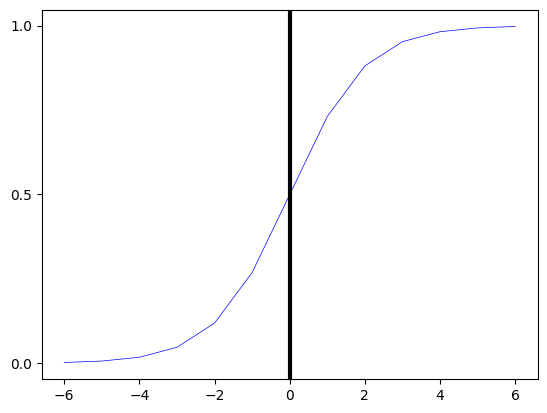

In [25]:
# 그래프 적용을 위한 데이터 만들기
sigmoid_x = range(-6, 7)
sigmoid_y = sigmoid(np.array(sigmoid_x))


# 선 그래프 그리기
plt.plot(sigmoid_x , sigmoid_y, color = 'blue',linewidth = 0.5)
# 백 그라운드 모눈 종이 설정하기
plt.rcParams['axes.grid'] = True
# 라인 굵기 설정하기
plt.axvline(x=0, color='black', linewidth=3)
# y 축 범위 설정하기
plt.yticks([0,0.5,1])
plt.show()

### 2) 로지스틱 회귀 실습하기

#### (1) 데이터 구성하기

In [26]:
# 학습 데이터 생성하기
x_train = [3,4,5,6,7,8,9,10,11,12,13,14,15,16,17]
y_train = [0,0,0,0,0,0,0,1,1,1,1,1,1,1,1]
# 추론을 위한 데이터 생성하기
x_test = [0,1,2,18,19]
y_test =  [0,0,0,1,1]

# 학습 데이터에 대해 numpy로 변경 및 행을 열로 변경하기
x_train = np.array(x_train).reshape([-1,1])
y_train = np.array(y_train)
# 추론 데이터에 대해 numpy로 변경 및 행을 열로 변경하기
x_test = np.array(x_test).reshape([-1,1])
y_test = np.array(y_test)

# 데이터 확인하기
print(x_train)
print(y_train)

[[ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]
 [11]
 [12]
 [13]
 [14]
 [15]
 [16]
 [17]]
[0 0 0 0 0 0 0 1 1 1 1 1 1 1 1]


#### (2) 로지스틱 회귀 학습 하기

In [28]:
#로지스틱 회귀 라이브러리 불러오기
from sklearn.linear_model import LogisticRegression

# 로지스틱 회귀 생성하기
logi_reg = LogisticRegression()

# 학습하기
logi_reg.fit(x_train, y_train)


# 역산을 위한 기울기와 절편이 있는지 확인하기
print('coef:', logi_reg.coef_)
print('intercept:', logi_reg.intercept_)

coef: [[1.19388731]]
intercept: [-11.34176791]


#### (3) 로지스틱 회귀 그래프 만들기


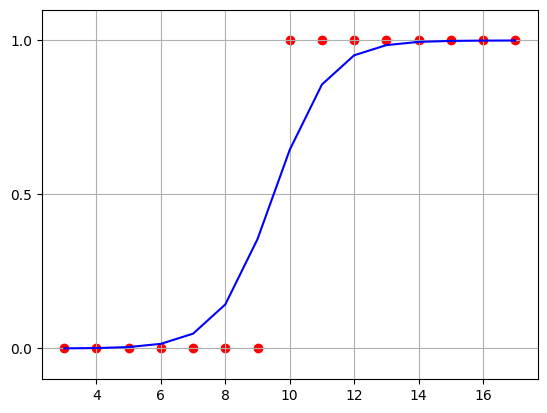

In [29]:
# 기울기와 절편을 수동으로 결과 만들기
odd = [] #
for i in x_train:
    odd.append((logi_reg.coef_* i) + logi_reg.intercept_)

sigmoid_y= sigmoid(np.array(odd))
sigmoid_y = sigmoid_y.reshape(-1,1)


# 역산된 그래프 표시하기
plt.scatter(x_train, y_train,color='red')
plt.plot(np.array(x_train), sigmoid_y, color='blue')
plt.rcParams['axes.grid'] = True
plt.yticks([0,0.5,1])
plt.ylim([-0.1, 1.1]) # y축의 범위: [Ymin, Ymax]
plt.show()

### 3) 로지스틱 회귀와 선형회귀 비교하기

#### (1) 선형회귀 모델링하기

In [34]:
# 선형회귀 함수 불러오기
from sklearn.linear_model import LinearRegression
# 선형회귀 생성하기
lr = LinearRegression()
# 학습하기
lr.fit(x_train,y_train)

# 수식 완성을 위한 coef 와 intercept 확인하기
print('intercept:', lr.intercept_)
print('coef:', lr.coef_)

intercept: -0.4666666666666667
coef: [0.1]


#### (2) 선형회귀 모델과 로지스틱 회귀 모델 비교하기

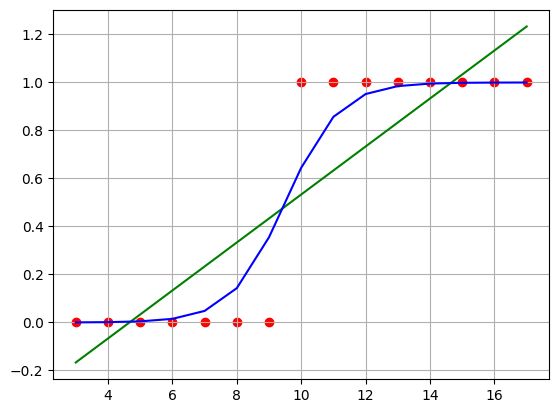

x_test: [[ 0]
 [ 1]
 [ 2]
 [18]
 [19]] y_test: [0 0 0 1 1]
로지스틱 회귀 정확도:  1.0
선형 회귀 정확도:  0.3981481481481479


In [36]:
coef_intercept = x_train * lr.coef_ + lr.intercept_

plt.scatter(x_train, y_train,color='red')
plt.plot(np.array(x_train), coef_intercept, color='green')
plt.plot(np.array(x_train), sigmoid_y, color='blue')
plt.rcParams['axes.grid'] = True
plt.show()
print('x_test:', x_test, 'y_test:', y_test)
print('로지스틱 회귀 정확도: ', logi_reg.score(x_test,y_test))
print('선형 회귀 정확도: ',lr.score(x_test,y_test))

### [확인 문제]

In [37]:
# 문제 01. 정답
logi_pred = logi_reg.predict(np.array(9.5).reshape(-1,1))
lr_pred = lr.predict(np.array(9.5).reshape(-1,1))
print('로직스틱 회귀 예측값(9.5): ', logi_pred)
print('선형 회귀 예측값(9.5): ', round(lr_pred[0]))

로직스틱 회귀 예측값(9.5):  [1]
선형 회귀 예측값(9.5):  0


### **[LLM 실습] 로지스틱 회귀의 '확률'과 LLM의 '확률' 비교**

> LLM의 다음 토큰 생성도 관점에 따라 보면 “**수만 개 Vocabulary 중 다음에 올 토큰 하나를 선택하는 거대한 Multi-Class Classification**”으로 이해할 수 있음
>> LLM도 결국 마지막에 Vocabulary 전체의 Logit(점수화한 것들) → Softmax(확률화) → 다음 토큰 선택을 한다.

- [주의~] GPU로 런타임 유형 변경 후 실행

In [2]:
import torch
import transformers

print("PyTorch :", torch.__version__)
print("Transformers :", transformers.__version__)
print("CUDA 사용 가능 :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

PyTorch : 2.11.0+cu128
Transformers : 5.17.0
CUDA 사용 가능 : True
GPU : Tesla T4


In [1]:
# ============================================================
# 1. 라이브러리 설치
# ============================================================
!pip install -q -U "transformers>=4.52.4" accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 20.1 MB/s eta 0:00:00


In [22]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# ============================================================
# 1. 환경 확인
# ============================================================

print("PyTorch :", torch.__version__)
print("CUDA :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))


# ============================================================
# 2. 모델 로드
# ============================================================

model_name = "Qwen/Qwen3-0.6B"

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="cuda"
)

model.eval()


PyTorch : 2.11.0+cu128
CUDA : True
GPU : Tesla T4


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 1024)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear(in_features=1024, out_features=2048, bias=False)
          (k_proj): Linear(in_features=1024, out_features=1024, bias=False)
          (v_proj): Linear(in_features=1024, out_features=1024, bias=False)
          (o_proj): Linear(in_features=2048, out_features=1024, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear(in_features=1024, out_features=3072, bias=False)
          (up_proj): Linear(in_features=1024, out_features=3072, bias=False)
          (down_proj): Linear(in_features=3072, out_features=1024, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((1024,), eps=1e-06)
        (post_attention_layer

In [23]:
# ============================================================
# 3. 입력 문장
# ============================================================

text = "오늘 날씨가 정말"

inputs = tokenizer(
    text,
    return_tensors="pt"
).to(model.device)


# ============================================================
# 4. 다음 토큰 Logit
# ============================================================

with torch.no_grad():

    outputs = model(**inputs)

    # 마지막 위치의 Vocabulary 전체 Logit
    logits = outputs.logits[0, -1, :]


# ============================================================
# 5. Logit → Softmax
# ============================================================

probs = torch.softmax(
    logits,
    dim=-1
)


# ============================================================
# 6. Top-5 다음 토큰
# ============================================================

top_probs, top_ids = torch.topk(
    probs,
    k=5
)


# ============================================================
# 7. 출력
# ============================================================

print("\n입력 문장 :", text)

print("\n다음 토큰 후보")
print("=" * 45)

for prob, token_id in zip(top_probs, top_ids):

    token = tokenizer.decode(
        [token_id.item()]
    )

    print(
        f"{repr(token):15s} "
        f"확률 = {prob.item():.6f}"
    )



입력 문장 : 오늘 날씨가 정말

다음 토큰 후보
' 좋'            확률 = 0.206787
' 좋아'           확률 = 0.068176
' �'            확률 = 0.053925
' �'            확률 = 0.045776
' 어'            확률 = 0.040710


#### **[Quiz] temperature를 바꾸면 확률 분포가 어떻게 평평해지는가? (logits / T)**

Vocabulary 크기 : 151936

입력 문장 : 오늘 날씨가 정말

Temperature에 따른 다음 토큰 확률
Token          T=0.5     T=1.0     T=2.0     
----------------------------------------------------------------------
' 좋'           0.7051    0.2068    0.0154    
' 좋아'          0.0767    0.0682    0.0089    
' �'           0.0480    0.0539    0.0079    
' �'           0.0345    0.0458    0.0073    
' 어'           0.0273    0.0407    0.0069    
' �'           0.0171    0.0322    0.0061    
' 좋은'          0.0156    0.0307    0.0060    
' 아'           0.0129    0.0280    0.0057    
' 기'           0.0087    0.0230    0.0052    
' �'           0.0064    0.0197    0.0048    


/tmp/ipykernel_2229/1984893456.py:162: UserWarning: Glyph 65533 (\N{REPLACEMENT CHARACTER}) missing from font(s) NanumBarunGothic.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65533 (\N{REPLACEMENT CHARACTER}) missing from font(s) NanumBarunGothic.
  fig.canvas.print_figure(bytes_io, **kw)


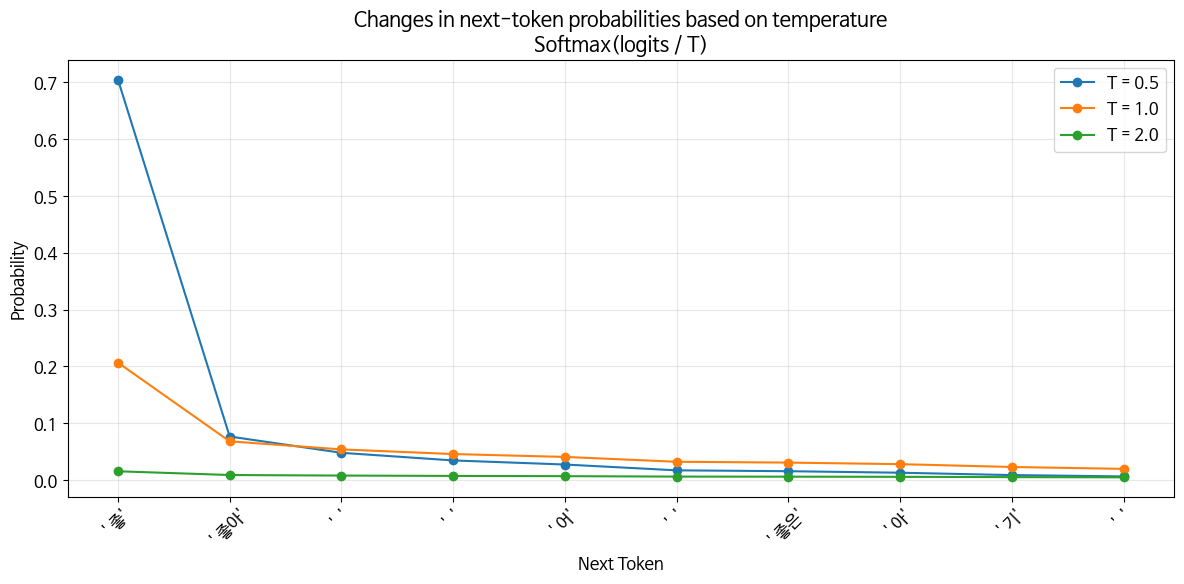

In [24]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 입력 문장
# ============================================================

text = "오늘 날씨가 정말"

inputs = tokenizer(
    text,
    return_tensors="pt"
).to(model.device)


# ============================================================
# 1. 모델에서 Logit 얻기
# ============================================================

with torch.no_grad():
    outputs = model(**inputs)

    # 마지막 위치의 Vocabulary 전체 Logit
    logits = outputs.logits[0, -1, :]


print("Vocabulary 크기 :", len(logits))


# ============================================================
# 2. 비교할 Temperature
# ============================================================
temperatures = [0.5, 1.0, 2.0]


# ============================================================
# 3. 원래 Logit 기준 Top-10 토큰 선택
#
# 같은 토큰들의 확률이 Temperature에 따라
# 어떻게 달라지는지 비교하기 위해 Top-10을 먼저 고정
# ============================================================

top_k = 10

base_probs = torch.softmax(logits, dim=-1)

_, top_ids = torch.topk(
    base_probs,
    k=top_k
)


# ============================================================
# 4. Temperature별 확률 계산
# ============================================================

results = {}

for T in temperatures:

    # 핵심!
    scaled_logits = logits / T

    probs = torch.softmax(
        scaled_logits,
        dim=-1
    )

    # Top-10 토큰의 확률만 추출
    top_probs = probs[top_ids]

    results[T] = top_probs.cpu().float().numpy()


# ============================================================
# 5. 토큰 이름 확인
# ============================================================

tokens = []

for token_id in top_ids:

    token = tokenizer.decode(
        [token_id.item()]
    )

    tokens.append(token)


# ============================================================
# 6. 결과 출력
# ============================================================

print("\n입력 문장 :", text)

print("\n" + "=" * 70)
print("Temperature에 따른 다음 토큰 확률")
print("=" * 70)

header = f"{'Token':15s}"

for T in temperatures:
    header += f"T={T:<8}"

print(header)

print("-" * 70)


for i, token in enumerate(tokens):

    line = f"{repr(token):15s}"

    for T in temperatures:
        line += f"{results[T][i]:<10.4f}"

    print(line)


# 그래프로 확인
# ============================================================
# 7. Temperature별 확률 분포 시각화
# ============================================================

x = np.arange(len(tokens))


plt.figure(figsize=(12, 6))


for T in temperatures:

    plt.plot(
        x,
        results[T],
        marker="o",
        label=f"T = {T}"
    )


plt.xticks(
    x,
    [repr(t) for t in tokens],
    rotation=45
)

plt.xlabel("Next Token")
plt.ylabel("Probability")

plt.title(
    "Changes in next-token probabilities based on temperature\n"
    "Softmax(logits / T)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

---------------------